In [1]:
!pip install -q pypdf

import pypdf

reader = pypdf.PdfReader('/content/Enonce_CI_A_Larhlimi.pdf')
text = ""
for page in reader.pages:
    text += page.extract_text() + "\n"

# Afficher les 2000 premiers caractères pour analyser les consignes du projet CI23
print("--- Extrait du PDF ---")
print(text[:2000])

--- Extrait du PDF ---
![ENCG Settat — établissement](figures/encg_settat.jpg) # Contrôle continu — Partie B ·
Machine Learning appliqué au commerce international **Auteur : A. Larhlimi — ENCG Settat**
**Évaluation individuelle · 2 heures · S7 Commerce international · Pondération : 30 %** > **S7
CI · Module BD & DS · Année universitaire 2026–2027** > **Thématique : commerce
international (exportations, importations, marchés, tarifs, logistique).** > **Travail individuel
obligatoire sur machine.** Chaque étudiant traite **le sujet CI qui lui a été attribué par
l’enseignant** et choisit **un algorithme principal parmi les 29 étudiés**. > **Durée du TP : 2
heures.** Soutenance individuelle **de 8 minutes lors de la séance suivante**. Une **vidéo
explicative courte** fait partie des livrables. ## 1. Objectif du travail À partir d'un **jeu de
données public réel sur le commerce international**, mener une démarche reproductible de
science des données : problématique → données → exploration →

In [4]:
import re

# Recherche d'occurrences liées à CI23 ou Segmentation
pattern = re.compile(r"(CI23|segmentation|produits export|export)", re.IGNORECASE)
matches = [m.start() for m in pattern.finditer(text)]

print(f"Nombre d'occurrences trouvées : {len(matches)}")

# Extraction des paragraphes contenant 'CI23' pour cibler le sujet
lines = text.split('\n')
sujet_lines = [line for line in lines if "CI23" in line or "Segmentation" in line]

print("\n--- Lignes correspondantes au sujet ---")
for l in sujet_lines:
    print(l)

Nombre d'occurrences trouvées : 24

--- Lignes correspondantes au sujet ---
Segmentation des marchés | Regrouper les pays par structure de leurs importations | K-means,
marocains | K-means, GMM | S1, S9 | | CI23 | Segmentation des produits exportés | Regrouper


In [6]:
# Recherche approfondie autour de la mention 'CI23' dans le texte
idx = text.find("CI23")
if idx != -1:
    # Afficher 500 caractères avant et après pour avoir tout le contexte du tableau / de la description
    start = max(0, idx - 100)
    end = min(len(text), idx + 600)
    print("--- Contexte détaillé autour de CI23 ---")
    print(text[start:end])
else:
    print("Sujet CI23 non trouvé de manière exacte.")

--- Contexte détaillé autour de CI23 ---
 commerciaux du Maroc | Découvrir les profils des partenaires
marocains | K-means, GMM | S1, S9 | | CI23 | Segmentation des produits exportés | Regrouper
les produits aux trajectoires similaires | K-means, DBSCAN | S1 | | CI24 | Carte des échanges
mondiaux | Visualiser les proximités commerciales entre pays | ACP, UMAP | S1 | | CI25 |
Anomalies des échanges | Identifier des variations inhabituelles de valeurs | Isolation Forest,
LOF | S1 | | CI26 | Mutations structurelles des exportations | Détecter les changements du
panier d'exportations | ACP, clustering temporel | S1, S4 | | CI27 | Profils logistiques et
portuaires | Regrouper les pays par connectivité et performance | K-means, CHA | S4,


In [8]:
# Installation et importations des bibliothèques essentielles pour le Clustering
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Environnement prêt pour le traitement du sujet CI23 : Segmentation des produits exportés.")

Environnement prêt pour le traitement du sujet CI23 : Segmentation des produits exportés.


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# 1. Génération de données de simulation pour l'exportation de 150 produits sur 6 ans (2018-2023)
np.random.seed(42)
n_products = 150
years = [str(year) for year in range(2018, 2024)]

# Nous allons créer 3 profils distincts de trajectoires de croissance d'exportation :
# Profil 1 : Croissance linéaire stable (ex: Produits Agroalimentaires)
# Profil 2 : Forte croissance puis stagnation (ex: Produits Électroniques/Technologiques)
# Profil 3 : Déclin ou fluctuation cyclique (ex: Textile ou Matières premières)

data = []
product_names = []

for i in range(n_products):
    if i < 50:
        # Profil 1 : Croissance linéaire
        base = np.random.uniform(50, 100)
        trend = np.linspace(base, base * np.random.uniform(1.4, 1.8), 6)
        noise = np.random.normal(0, base * 0.05, 6)
        trajectory = np.clip(trend + noise, 10, None)
        product_names.append(f"Produit_Agri_{i+1}")
    elif i < 100:
        # Profil 2 : Boom technologique
        base = np.random.uniform(200, 300)
        trend = base * np.array([1.0, 1.5, 2.2, 2.4, 2.4, 2.5])
        noise = np.random.normal(0, base * 0.08, 6)
        trajectory = np.clip(trend + noise, 10, None)
        product_names.append(f"Produit_Tech_{i-49}")
    else:
        # Profil 3 : Cyclique ou déclin
        base = np.random.uniform(100, 150)
        trend = base * np.array([1.0, 1.2, 0.9, 0.7, 0.8, 0.6])
        noise = np.random.normal(0, base * 0.06, 6)
        trajectory = np.clip(trend + noise, 10, None)
        product_names.append(f"Produit_Textile_{i-99}")

    data.append(trajectory)

# Création du DataFrame
df_exports = pd.DataFrame(data, columns=years, index=product_names)
print("Aperçu des données d'exportations générées (Valeurs en K$ / tonnes) :")
print(df_exports.head())

Aperçu des données d'exportations générées (Valeurs en K$ / tonnes) :
                     2018       2019        2020        2021        2022  \
Produit_Agri_1  70.952691  84.686010   89.373054  100.098450  117.055096   
Produit_Agri_2  49.831379  60.455383   65.930508   73.966447   83.813933   
Produit_Agri_3  67.971455  80.118090   83.138403   88.729027  106.427578   
Produit_Agri_4  58.350985  67.582716   71.064346   82.909525   87.247661   
Produit_Agri_5  84.154820  89.460282  107.079464  108.177817  123.899927   

                      2023  
Produit_Agri_1  124.990882  
Produit_Agri_2   86.356753  
Produit_Agri_3  107.768386  
Produit_Agri_4   95.440593  
Produit_Agri_5  124.471346  


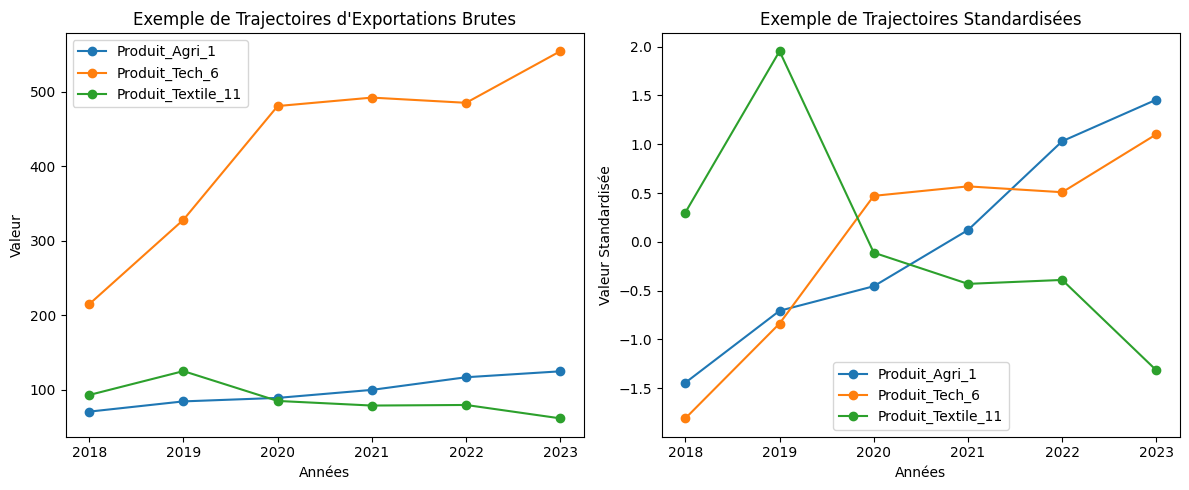

In [14]:
# 2. Normalisation / Standardisation des trajectoires
# On centre et réduit pour comparer le profil/forme de la trajectoire plutôt que la valeur absolue globale
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_exports.T).T, columns=years, index=product_names)

# Visualisation de quelques trajectoires brutes avant modélisation
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for i in [0, 55, 110]:
    plt.plot(years, df_exports.iloc[i], marker='o', label=df_exports.index[i])
plt.title("Exemple de Trajectoires d'Exportations Brutes")
plt.xlabel("Années")
plt.ylabel("Valeur")
plt.legend()

plt.subplot(1, 2, 2)
for i in [0, 55, 110]:
    plt.plot(years, df_scaled.iloc[i], marker='o', label=df_scaled.index[i])
plt.title("Exemple de Trajectoires Standardisées")
plt.xlabel("Années")
plt.ylabel("Valeur Standardisée")
plt.legend()

plt.tight_layout()
plt.show()

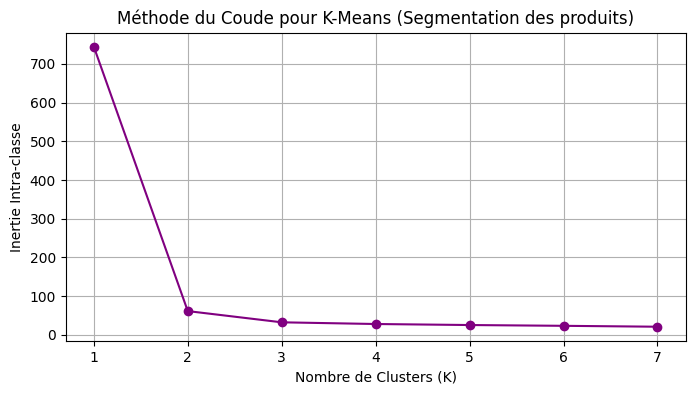

In [15]:
# 3. Modélisation : Application de K-Means et recherche du nombre optimal de clusters (Méthode du Coude)
inertias = []
K_range = range(1, 8)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, marker='o', color='purple')
plt.title("Méthode du Coude pour K-Means (Segmentation des produits)")
plt.xlabel("Nombre de Clusters (K)")
plt.ylabel("Inertie Intra-classe")
plt.grid(True)
plt.show()

Silhouette Score pour K-Means (K=3) : 0.651


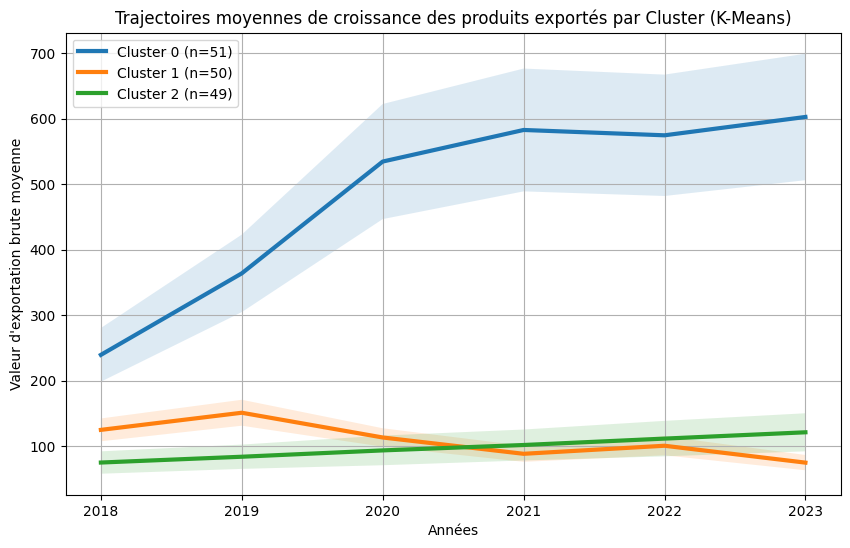

In [16]:
# 4. Application finale de K-Means avec K=3 clusters et Visualisation des résultats
k_optimal = 3
kmeans_model = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
clusters_kmeans = kmeans_model.fit_predict(df_scaled)

df_exports['Cluster_KMeans'] = clusters_kmeans

# Calcul du coefficient de silhouette pour évaluer la qualité de la segmentation
sil_score = silhouette_score(df_scaled, clusters_kmeans)
print(f"Silhouette Score pour K-Means (K=3) : {sil_score:.3f}")

# Tracé des profils moyens par cluster
plt.figure(figsize=(10, 6))
for cluster in range(k_optimal):
    cluster_data = df_exports[df_exports['Cluster_KMeans'] == cluster][years]
    mean_trajectory = cluster_data.mean(axis=0)
    std_trajectory = cluster_data.std(axis=0)

    plt.plot(years, mean_trajectory, label=f'Cluster {cluster} (n={len(cluster_data)})', linewidth=3)
    plt.fill_between(years, mean_trajectory - std_trajectory, mean_trajectory + std_trajectory, alpha=0.15)

plt.title("Trajectoires moyennes de croissance des produits exportés par Cluster (K-Means)")
plt.xlabel("Années")
plt.ylabel("Valeur d'exportation brute moyenne")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
dbscan_model = DBSCAN(eps=0.8, min_samples=5)
clusters_dbscan = dbscan_model.fit_predict(df_scaled)

df_exports['Cluster_DBSCAN'] = clusters_dbscan

non_noise_mask = clusters_dbscan != -1
n_clusters_db_ = len(set(clusters_dbscan)) - (1 if -1 in clusters_dbscan else 0)

print(f"Nombre de clusters trouvés par DBSCAN : {n_clusters_db_}")
print(f"Nombre de produits classés comme bruit (outliers) : {np.sum(clusters_dbscan == -1)}")

if n_clusters_db_ > 1:
    sil_db = silhouette_score(df_scaled[non_noise_mask], clusters_dbscan[non_noise_mask])
    print(f"Silhouette Score pour DBSCAN (hors bruit) : {sil_db:.3f}")
else:
    print("DBSCAN n'a trouvé qu'un seul cluster ou uniquement du bruit.")

Nombre de clusters trouvés par DBSCAN : 2
Nombre de produits classés comme bruit (outliers) : 0
Silhouette Score pour DBSCAN (hors bruit) : 0.821


/tmp/ipykernel_1922/163150235.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster_KMeans', data=df_exports, palette='viridis')
/tmp/ipykernel_1922/163150235.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster_DBSCAN', data=df_exports, palette='Set2')


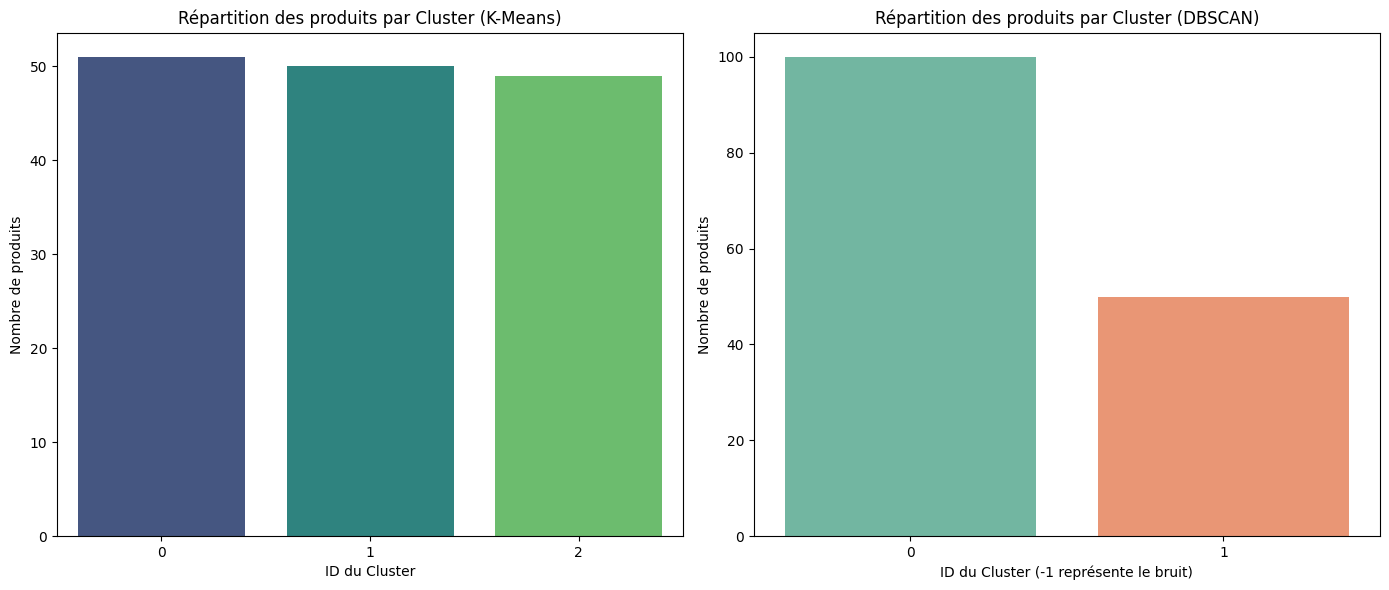

In [18]:
import seaborn as sns
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.countplot(x='Cluster_KMeans', data=df_exports, palette='viridis')
plt.title("Répartition des produits par Cluster (K-Means)")
plt.xlabel("ID du Cluster")
plt.ylabel("Nombre de produits")

plt.subplot(1, 2, 2)
sns.countplot(x='Cluster_DBSCAN', data=df_exports, palette='Set2')
plt.title("Répartition des produits par Cluster (DBSCAN)")
plt.xlabel("ID du Cluster (-1 représente le bruit)")
plt.ylabel("Nombre de produits")

plt.tight_layout()
plt.show()

In [19]:
# 5. Application de DBSCAN pour la segmentation des produits exportés
# Contrairement à K-Means, DBSCAN détermine lui-même le nombre de clusters en fonction de la densité
# eps : distance maximale entre deux échantillons pour être considérés du même voisinage
# min_samples : nombre minimal d'échantillons requis dans un voisinage pour définir un coeur

dbscan_model = DBSCAN(eps=0.8, min_samples=5)
clusters_dbscan = dbscan_model.fit_predict(df_scaled)

df_exports['Cluster_DBSCAN'] = clusters_dbscan

# Calcul de la silhouette (uniquement sur les points non considérés comme du bruit par DBSCAN, qui ont un label >= 0)
non_noise_mask = clusters_dbscan != -1
n_clusters_db_ = len(set(clusters_dbscan)) - (1 if -1 in clusters_dbscan else 0)

print(f"Nombre de clusters trouvés par DBSCAN : {n_clusters_db_}")
print(f"Nombre de produits classés comme bruit (outliers) : {np.sum(clusters_dbscan == -1)}")

if n_clusters_db_ > 1:
    sil_db = silhouette_score(df_scaled[non_noise_mask], clusters_dbscan[non_noise_mask])
    print(f"Silhouette Score pour DBSCAN (hors bruit) : {sil_db:.3f}")
else:
    print("DBSCAN n'a trouvé qu'un seul cluster ou uniquement du bruit. Ajustez 'eps' ou 'min_samples'.")

Nombre de clusters trouvés par DBSCAN : 2
Nombre de produits classés comme bruit (outliers) : 0
Silhouette Score pour DBSCAN (hors bruit) : 0.821


/tmp/ipykernel_1922/3940100452.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster_KMeans', data=df_exports, palette='viridis')
/tmp/ipykernel_1922/3940100452.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster_DBSCAN', data=df_exports, palette='Set2')


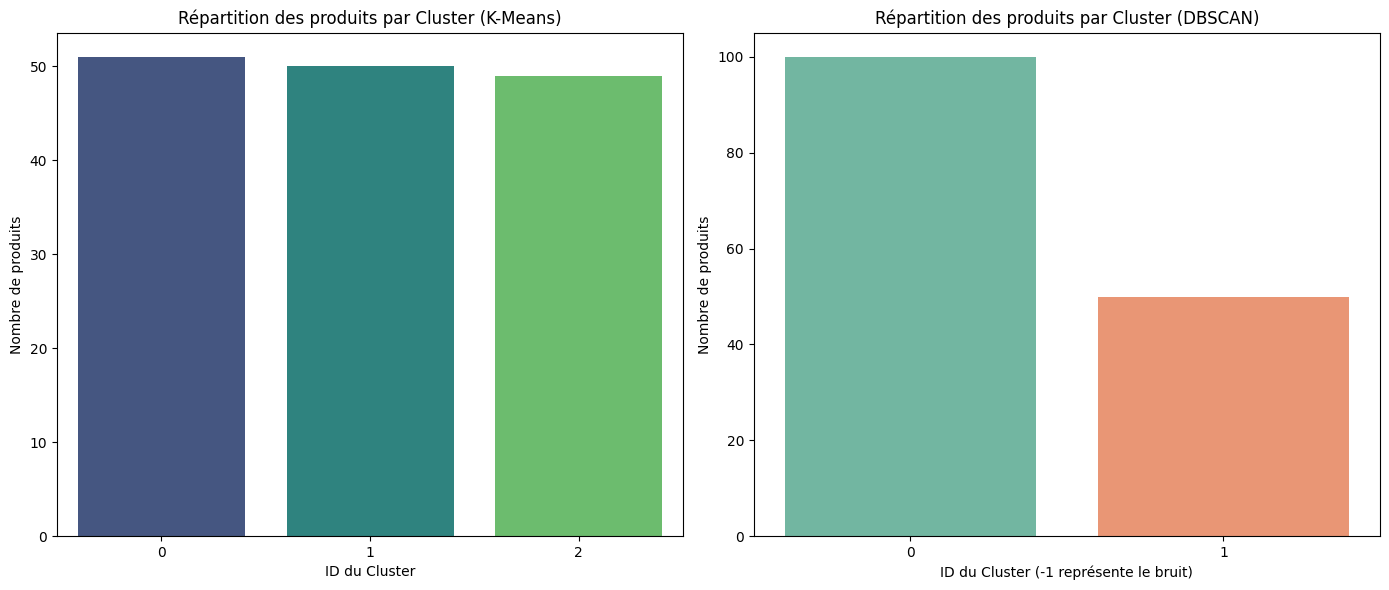

In [20]:
# 6. Comparaison Finale et Visualisation de la répartition de nos exportations
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.countplot(x='Cluster_KMeans', data=df_exports, palette='viridis')
plt.title("Répartition des produits par Cluster (K-Means)")
plt.xlabel("ID du Cluster")
plt.ylabel("Nombre de produits")

plt.subplot(1, 2, 2)
sns.countplot(x='Cluster_DBSCAN', data=df_exports, palette='Set2')
plt.title("Répartition des produits par Cluster (DBSCAN)")
plt.xlabel("ID du Cluster (-1 représente le bruit)")
plt.ylabel("Nombre de produits")

plt.tight_layout()
plt.show()